# LDA Pfam

Ce notebook realise le preprocessing, la LDA et le K-means sur la famille de descripteurs Pfam.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

random_state = 42
n_init = 20

## Chargement et preprocessing

In [2]:
X_train = pd.read_csv('../Données/X_train_clean.csv')
y_train = pd.read_csv('../Données/Y_train_clean.csv')

print(f'Shape de X_train : {X_train.shape}')
print(f'Valeurs manquantes : {X_train.isna().sum().sum()}')

num_cols = X_train.select_dtypes(include=['float64', 'int64']).columns
X_num = X_train[num_cols]

numeric_cols = X_num.columns.tolist()
print(f"Colonnes numériques : {numeric_cols}")

Shape de X_train : (444, 34)
Valeurs manquantes : 0
Colonnes numériques : ['Family_Size', 'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Distance', 'TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 'TE_Number_Mean', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean', 'Pfam_Asymmetry', 'Pfam_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean', 'TE_Env_Match', 'Expression_Data_Missing']


In [3]:
X_train['TE_Coverage_Mean'].describe()

count    444.000000
mean       5.563647
std        6.651536
min        0.000000
25%        0.000000
50%        3.602688
75%        8.576138
max       47.548340
Name: TE_Coverage_Mean, dtype: float64

## Linear Discriminant Analysis

In [4]:
# Conserver uniquement les variables Pfam
pfam_columns = [
    column for column in X_num.columns
    if column.startswith("Pfam_")
]
pfam_columns.append('Family_Size')

if not pfam_columns:
    raise ValueError("Aucune colonne Pfam trouvée dans X_num.")

X_all = X_num[pfam_columns].copy()
y = y_train['Classification'].reset_index(drop=True)
X_all = X_all.reset_index(drop=True)

if len(X_all) != len(y):
    raise ValueError('X_all et y_train n ont pas le meme nombre de lignes.')

scaler_lda = StandardScaler()
X_all_scaled = scaler_lda.fit_transform(X_all)

n_components = min(2, len(y_train['Classification'].dropna().unique()) - 1)
lda = LinearDiscriminantAnalysis(n_components=n_components)
X_lda = lda.fit_transform(X_all_scaled, y_train['Classification'])

if n_components == 1:
    df_lda = pd.DataFrame({'LDA_1': X_lda[:, 0], 'Classification': y_train['Classification']})
else:
    df_lda = pd.DataFrame(X_lda, columns=['LDA_1', 'LDA_2'])
    df_lda['Classification'] = y_train['Classification']

print('Shape apres LDA :', X_lda.shape)

Shape apres LDA : (444, 1)


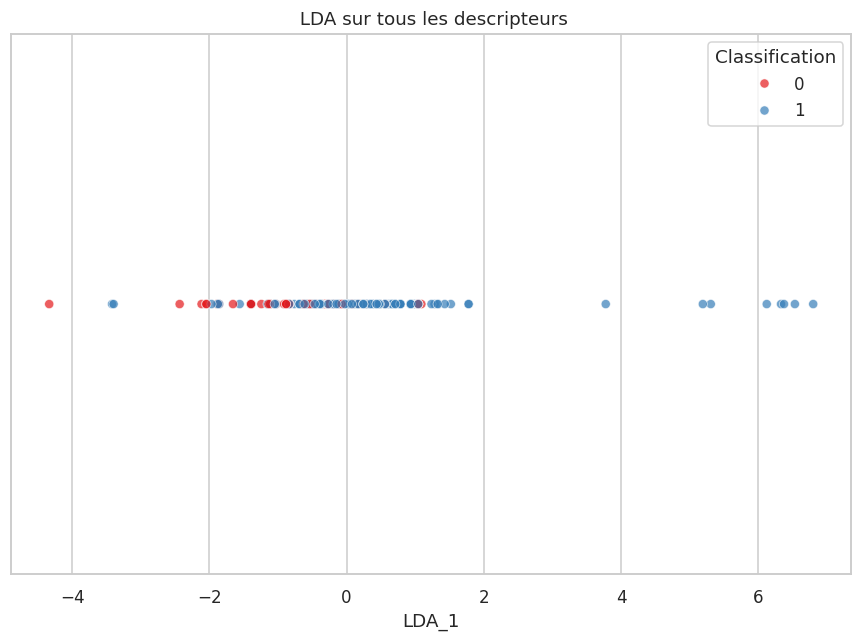

In [5]:
plt.figure(figsize=(8, 6))
if n_components == 1:
    sns.scatterplot(
        data=df_lda, x='LDA_1', y=np.zeros(len(df_lda)),
        hue='Classification', palette='Set1', alpha=0.7
    )
    plt.ylabel('')
    plt.yticks([])
else:
    sns.scatterplot(
        data=df_lda, x='LDA_1', y='LDA_2',
        hue='Classification', palette='Set1', alpha=0.7
    )
plt.title(' LDA sur tous les descripteurs')
plt.tight_layout()
plt.show()

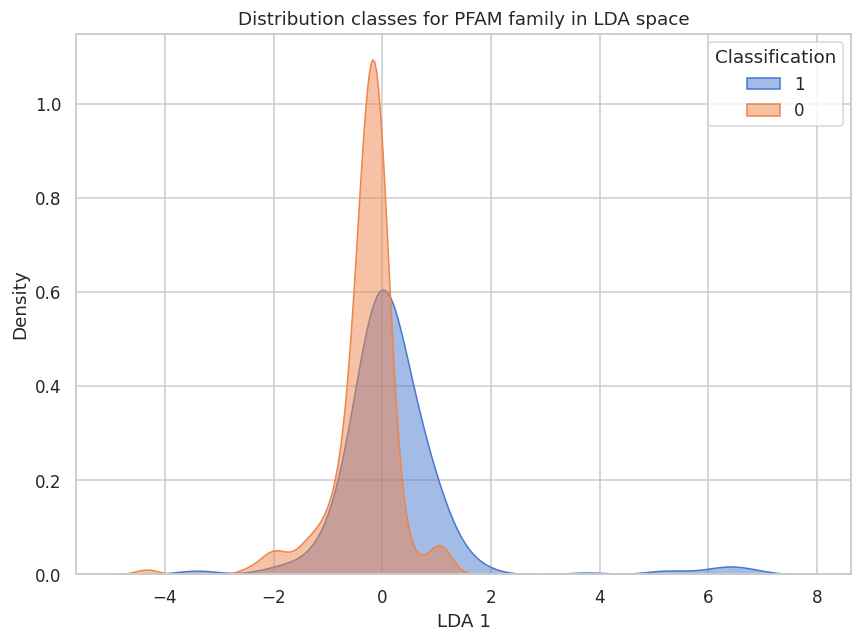

In [6]:
plt.figure(figsize=(8, 6))
if n_components == 1:
    for cls in df_lda['Classification'].unique():
        sns.kdeplot(df_lda[df_lda['Classification'] == cls]['LDA_1'], label=cls, fill=True, alpha=0.5)
    plt.xlabel('LDA 1')
else:
    for cls in df_lda['Classification'].unique():
        sns.kdeplot(
            x=df_lda[df_lda['Classification'] == cls]['LDA_1'],
            y=df_lda[df_lda['Classification'] == cls]['LDA_2'],
            label=cls,
            fill=True,
            alpha=0.5
        )
    plt.xlabel('LDA 1')
    plt.ylabel('LDA 2')
plt.title('Distribution classes for PFAM family in LDA space')
plt.legend(title='Classification')
plt.savefig('Plots/appendix_functional_fate/lda_pfam_distribution.png', dpi=300)
plt.tight_layout()
plt.show()

In [7]:
coef_df = pd.DataFrame(lda.coef_, columns=X_all.columns).T
coef_df['max_abs_coef'] = coef_df.abs().max(axis=1)
coef_df_sorted = coef_df.sort_values('max_abs_coef', ascending=False)

print('Tableau des 10 meilleurs coefficients de la LDA :')
coef_df_sorted.head(10)

Tableau des 10 meilleurs coefficients de la LDA :


,0,max_abs_coef
Family_Size,0.628596,0.628596
Pfam_Union,-0.440163,0.440163
Pfam_Asymmetry,0.213125,0.213125
Pfam_Mean,-0.192262,0.192262
Pfam_Inter,0.144314,0.144314
Pfam_Jaccard,-0.108162,0.108162


## K-means sur les cinq meilleurs descripteurs

### Selection dynamique des meilleurs descripteurs

On repart du classement `coef_df_sorted` etabli par la LDA (coefficient absolu maximal), puis on garde les premiers.


In [8]:
ranking_no_mean = coef_df_sorted[~coef_df_sorted.index.str.endswith('_Mean')]
selected_descriptors = ranking_no_mean.head(5).index.tolist()

print('Descripteurs selectionnes :')
print(selected_descriptors)

missing_descriptors = [
    column for column in selected_descriptors
    if column not in X_train.columns
]
if missing_descriptors:
    raise KeyError(f'Descripteurs absents : {missing_descriptors}')


Descripteurs selectionnes :
['Family_Size', 'Pfam_Union', 'Pfam_Asymmetry', 'Pfam_Inter', 'Pfam_Jaccard']


## Pipeline K-means par descripteur

**Hypotheses retenues pour le tableau recapitulatif** :
- Plage de K testee : 1 a 10 (un K est ignore s'il est superieur ou egal au nombre de points disponibles).
- *ARI moyen / ARI median* : mesure de stabilite. Le K-means est relance `n_stability_runs` fois avec des graines aleatoires differentes pour le meme K, puis l'ARI est calcule entre toutes les paires de partitions obtenues ; on rapporte la moyenne et la mediane de ces ARI.
- *BIC* : approximation gaussienne spherique classique (a la X-means / Pelleg & Moore), avec `p = (K-1) + K*d + 1` parametres libres (d = dimension, ici d = 1 par descripteur).
- *Partition non triviale ?* : vaut « Oui » si la plus petite taille de cluster est >= `min_cluster_size` (3 par defaut) **et** qu'aucun cluster ne depasse `max_cluster_frac` (90% par defaut) des points, « Non » sinon.
- Le K final retenu par descripteur est celui qui maximise la silhouette parmi les partitions non triviales (repli sur l'ensemble des partitions K>1 si aucune n'est non triviale).


In [18]:
from itertools import combinations

# Constantes ajustables
k_values = list(range(1, 11))
n_stability_runs = 10
min_cluster_size = 22 # 5% du nombre total de paires 
max_cluster_frac = 0.95


def compute_bic(X, labels, centers):
    """BIC approx gaussienne spherique (style X-means / Pelleg & Moore)."""
    n, d = X.shape
    k = centers.shape[0]
    n_i = np.bincount(labels, minlength=k).astype(float)

    ss = 0.0
    for i in range(k):
        pts = X[labels == i]
        if len(pts) > 0:
            ss += np.sum((pts - centers[i]) ** 2)

    dof = n - k
    if dof <= 0:
        return np.nan
    variance = ss / dof
    if variance <= 0:
        return np.nan

    log_lik = 0.0
    for i in range(k):
        if n_i[i] == 0:
            continue
        log_lik += (
            -n_i[i] / 2 * np.log(2 * np.pi)
            - n_i[i] * d / 2 * np.log(variance)
            - (n_i[i] - 1) / 2
            + n_i[i] * np.log(n_i[i])
            - n_i[i] * np.log(n)
        )

    n_params = (k - 1) + k * d + 1
    return log_lik - (n_params / 2) * np.log(n)


def kmeans_stability(X, k, n_runs, base_seed, n_init):
    """Relance le K-means n_runs fois (graines differentes) et calcule les ARI par paire."""
    labelings, inertias = [], []
    for run in range(n_runs):
        model = KMeans(n_clusters=k, n_init=n_init, random_state=base_seed + run)
        labels = model.fit_predict(X)
        labelings.append(labels)
        inertias.append(model.inertia_)
    aris = [
        adjusted_rand_score(a, b)
        for a, b in combinations(labelings, 2)
    ]
    return labelings, inertias, aris


def kmeans_grid_summary(X, k_values, n_runs=n_stability_runs, base_seed=random_state,
                         n_init=n_init, min_cluster_size=min_cluster_size,
                         max_cluster_frac=max_cluster_frac):
    """Construit le tableau recapitulatif Inertie/Silhouette/ARI/BIC pour une plage de K."""
    n = X.shape[0]
    rows = []

    for k in k_values:
        if k == 1:
            center = X.mean(axis=0, keepdims=True)
            inertia = float(np.sum((X - center) ** 2))
            rows.append({
                'K': k, 'Inertie': inertia, 'Silhouette': np.nan,
                'ARI moyen': np.nan, 'ARI median': np.nan,
                'Taille min': np.nan, 'Taille max': np.nan,
                'Partition non triviale ?': np.nan, 'BIC': np.nan
            })
            continue

        if k >= n:
            continue

        labelings, inertias, aris = kmeans_stability(X, k, n_runs, base_seed, n_init)
        best_idx = int(np.argmin(inertias))
        labels = labelings[best_idx]

        if len(set(labels)) < 2:
            continue

        sizes = np.bincount(labels, minlength=k)
        sil = silhouette_score(X, labels)

        final_model = KMeans(n_clusters=k, n_init=n_init, random_state=base_seed).fit(X)
        bic = compute_bic(X, labels, final_model.cluster_centers_)

        non_trivial = bool(
            sizes.min() >= min_cluster_size and sizes.max() / n <= max_cluster_frac
        )

        rows.append({
            'K': k,
            'Inertie': inertias[best_idx],
            'Silhouette': sil,
            'ARI moyen': float(np.mean(aris)) if aris else np.nan,
            'ARI median': float(np.median(aris)) if aris else np.nan,
            'Taille min': float(sizes.min()),
            'Taille max': float(sizes.max()),
            'Partition non triviale ?': 'Oui' if non_trivial else 'Non',
            'BIC': bic
        })

    return pd.DataFrame(rows)


### Boucle principale : premier cluster (Asymmetry) + grille K-means par descripteur


In [20]:
descriptor_summaries = {}
labels_by_descriptor = {}

X_all_scaled_df = pd.DataFrame(
    X_all_scaled,
    columns=X_all.columns,
    index=X_train.index
)

for descriptor in selected_descriptors:
    values_scaled = pd.to_numeric(
        X_all_scaled_df[descriptor],
        errors='coerce'
    )

    labels_full = pd.Series(
        index=X_train.index,
        dtype='Int64'
    )

    remaining_mask = values_scaled.notna()
    X_remaining_scaled = values_scaled.loc[
        remaining_mask
    ].to_numpy().reshape(-1, 1)

    if len(X_remaining_scaled) == 0:
        labels_by_descriptor[descriptor] = labels_full
        continue

    summary_df = kmeans_grid_summary(
        X_remaining_scaled,
        k_values
    )

    descriptor_summaries[descriptor] = summary_df

    print(f'Tableau récapitulatif K-means -- {descriptor}')
    display(summary_df)

    candidates = summary_df[summary_df['K'] > 1]
    non_trivial = candidates[
        candidates['Partition non triviale ?'] == 'Oui'
    ]

    if not non_trivial.empty:
        best_row = non_trivial.loc[
            non_trivial['Silhouette'].idxmax()
        ]
        best_k = int(best_row['K'])
    elif not candidates.empty:
        best_k = int(candidates['K'].min())
        print(
            f'Attention : aucune partition non triviale pour {descriptor} ; '
            f'le plus petit K testé ({best_k}) est retenu.'
        )
    else:
        labels_by_descriptor[descriptor] = labels_full.astype('Int64')
        continue

    final_model = KMeans(
        n_clusters=best_k,
        n_init=n_init,
        random_state=random_state
    )

    final_labels = final_model.fit_predict(
        X_remaining_scaled
    )

    labels_full.loc[
        values_scaled.loc[remaining_mask].index
    ] = final_labels

    print(f'K retenu pour {descriptor} : {best_k}')

    labels_by_descriptor[descriptor] = labels_full.astype('Int64')

Tableau récapitulatif K-means -- Family_Size


,K,Inertie,Silhouette,ARI moyen,ARI median,Taille min,Taille max,Partition non triviale ?,BIC
0,1,444.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,32.058998,0.964440,1.000000,1.000000,8.0,436.0,Non,-98.790410
2,3,9.898372,0.761895,1.000000,1.000000,8.0,390.0,Non,9.069723
3,4,3.217391,0.730422,1.000000,1.000000,8.0,296.0,Non,54.294554
4,5,1.679928,0.735024,1.000000,1.000000,8.0,287.0,Non,134.674671
5,6,0.882730,0.715305,0.998645,1.000000,8.0,237.0,Non,-810.441610
6,7,0.570217,0.725049,0.999391,1.000000,8.0,237.0,Non,-679.759670
7,8,0.365731,0.723661,0.995759,0.998468,8.0,196.0,Non,-1289.639858
8,9,0.245507,0.731362,0.861981,0.972707,8.0,196.0,Non,-827.922693
9,10,0.157884,0.791671,0.989805,1.000000,8.0,143.0,Non,211.964340


Attention : aucune partition non triviale pour Family_Size ; le plus petit K testé (2) est retenu.
K retenu pour Family_Size : 2
Tableau récapitulatif K-means -- Pfam_Union


,K,Inertie,Silhouette,ARI moyen,ARI median,Taille min,Taille max,Partition non triviale ?,BIC
0,1,444.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,126.837960,0.868731,1.000000,1.000000,18.0,426.0,Non,-439.383918
2,3,55.285252,0.759470,1.000000,1.000000,14.0,388.0,Non,-1529.871610
3,4,34.084681,0.684303,1.000000,1.000000,14.0,300.0,Non,-482.766486
4,5,20.717521,0.687302,0.624627,0.296834,8.0,300.0,Non,-1076.107833
5,6,13.680793,0.836413,0.983272,0.970587,8.0,170.0,Non,-1583.782122
6,7,8.493622,0.870544,0.999457,1.000000,7.0,170.0,Non,-439.865476
7,8,6.311301,0.869854,0.999888,1.000000,5.0,170.0,Non,-1898.821569
8,9,4.334132,0.912033,0.998628,0.998107,5.0,170.0,Non,-1557.571450
9,10,3.222412,0.913023,0.999380,0.999684,3.0,170.0,Non,-1929.336721


Attention : aucune partition non triviale pour Pfam_Union ; le plus petit K testé (2) est retenu.
K retenu pour Pfam_Union : 2


...

Attention : aucune partition non triviale pour Pfam_Asymmetry ; le plus petit K testé (2) est retenu.
K retenu pour Pfam_Asymmetry : 2
Tableau récapitulatif K-means -- Pfam_Inter


,K,Inertie,Silhouette,ARI moyen,ARI median,Taille min,Taille max,Partition non triviale ?,BIC
0,1,444.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,139.489615,0.803977,1.000000,1.000000,39.0,405.0,Oui,-517.256317
2,3,60.437108,0.750638,1.000000,1.000000,15.0,376.0,Non,-431.558514
3,4,33.364547,0.745416,1.000000,1.000000,15.0,200.0,Non,-1165.210041
4,5,21.515812,0.783752,0.999799,1.000000,12.0,191.0,Non,-1228.074262
5,6,13.727658,0.867614,0.999490,0.999043,11.0,191.0,Non,-502.340067
6,7,8.643783,0.870722,1.000000,1.000000,3.0,191.0,Non,-412.409251
7,8,6.310736,0.896767,1.000000,1.000000,3.0,191.0,Non,-383.958319
8,9,4.251131,0.940828,1.000000,1.000000,3.0,177.0,Non,-352.417884
9,10,2.906284,0.941865,0.999616,1.000000,3.0,177.0,Non,-281.094700


K retenu pour Pfam_Inter : 2
Tableau récapitulatif K-means -- Pfam_Jaccard


,K,Inertie,Silhouette,ARI moyen,ARI median,Taille min,Taille max,Partition non triviale ?,BIC
0,1,444.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,112.813678,0.861073,1.000000,1.0,69.0,375.0,Oui,-529.838806
2,3,27.319474,0.897484,1.000000,1.0,18.0,362.0,Non,-284.891067
3,4,11.028826,0.913678,1.000000,1.0,14.0,348.0,Non,-156.944396
4,5,4.485127,0.938837,0.998388,1.0,14.0,346.0,Non,-724.190617
5,6,2.063983,0.947396,1.000000,1.0,4.0,346.0,Non,150.248106
6,7,1.128887,0.952436,1.000000,1.0,4.0,346.0,Non,256.737607
7,8,0.727989,0.961323,1.000000,1.0,4.0,346.0,Non,336.604262
8,9,0.526798,0.961351,0.998015,1.0,3.0,345.0,Non,390.871594
9,10,0.396270,0.962228,0.999593,1.0,3.0,345.0,Non,-1294.556252


K retenu pour Pfam_Jaccard : 2


### Tailles de clusters finales (premier cluster inclus)


In [21]:
X_top_5 = X_train[selected_descriptors].copy()
scaler_top_5 = StandardScaler()
X_top_5_scaled = pd.DataFrame(
    scaler_top_5.fit_transform(X_top_5),
    columns=selected_descriptors,
    index=X_top_5.index
)

cluster_size_rows = []
for descriptor, labels in labels_by_descriptor.items():
    counts = labels.value_counts().sort_index()
    for cluster, size in counts.items():
        cluster_size_rows.append({
            'Descripteur': descriptor,
            'Cluster': int(cluster),
            'Taille': int(size)
        })

cluster_sizes_df = pd.DataFrame(cluster_size_rows)
display(cluster_sizes_df)


,Descripteur,Cluster,Taille
0,Family_Size,0,436
1,Family_Size,1,8
2,Pfam_Union,0,426
3,Pfam_Union,1,18
4,Pfam_Asymmetry,0,11
5,Pfam_Asymmetry,1,433
6,Pfam_Inter,0,405
7,Pfam_Inter,1,39
8,Pfam_Jaccard,0,69
9,Pfam_Jaccard,1,375


In [22]:
# Comparaison en conservant les identifiants réels des clusters

y_train = pd.read_csv("Données/Y_train_clean.csv")
classifications = y_train["Classification"].reset_index(drop=True)

cluster_sizes_by_descriptor = {}
cluster_ratios_by_descriptor = {}

# position du centre des clusters 

for descriptor in selected_descriptors:
    labels = labels_by_descriptor[descriptor].reset_index(drop=True)

    if len(labels) != len(classifications):
        raise ValueError(
            f"Nombre de labels incompatible pour {descriptor}."
        )

    valid_mask = labels.notna() & classifications.notna()

    labels_valid = labels.loc[valid_mask].astype(int)
    classifications_valid = classifications.loc[valid_mask]

    cluster_sizes = {}
    cluster_ratios = {}

    # Les identifiants réels sont conservés
    for cluster_id in sorted(labels_valid.unique()):
        cluster_mask = labels_valid == cluster_id

        n_points = int(cluster_mask.sum())
        n_redondant = int(
            ((classifications_valid == 0) & cluster_mask).sum()
        )
        n_divergent = int(
            ((classifications_valid == 1) & cluster_mask).sum()
        )

        ratio = (
            n_redondant / n_divergent
            if n_divergent > 0
            else np.inf
        )

        cluster_sizes[cluster_id] = n_points
        cluster_ratios[cluster_id] = ratio

    cluster_sizes_by_descriptor[descriptor] = cluster_sizes
    cluster_ratios_by_descriptor[descriptor] = cluster_ratios


# Nombre maximal d'identifiants de clusters
max_cluster_id = max(
    max(cluster_sizes.keys())
    for cluster_sizes in cluster_sizes_by_descriptor.values()
)

columns = [
    f"Cluster {cluster_id}"
    for cluster_id in range(max_cluster_id + 1)
]

cluster_comparison = pd.DataFrame(
    np.nan,
    index=selected_descriptors,
    columns=columns,
    dtype=float
)

ratio_comparison = pd.DataFrame(
    np.nan,
    index=selected_descriptors,
    columns=columns,
    dtype=float
)


# Remplissage selon les identifiants réels
for descriptor in selected_descriptors:
    cluster_sizes = cluster_sizes_by_descriptor[descriptor]
    cluster_ratios = cluster_ratios_by_descriptor[descriptor]

    for cluster_id in cluster_sizes:
        column = f"Cluster {cluster_id}"

        cluster_comparison.loc[
            descriptor, column
        ] = cluster_sizes[cluster_id]

        ratio_comparison.loc[
            descriptor, column
        ] = cluster_ratios[cluster_id]


# Annotations
annot_matrix = pd.DataFrame(
    "",
    index=cluster_comparison.index,
    columns=cluster_comparison.columns,
    dtype=object
)

for descriptor in cluster_comparison.index:
    for column in cluster_comparison.columns:
        n_points = cluster_comparison.loc[descriptor, column]
        ratio = ratio_comparison.loc[descriptor, column]

        if pd.isna(n_points):
            annot_matrix.loc[descriptor, column] = ""
        else:
            ratio_text = (
                f"{ratio:.2f}"
                if not np.isinf(ratio)
                else "inf"
            )

            annot_matrix.loc[descriptor, column] = (
                f"{int(n_points)} paires\n"
                f"R/D={ratio_text}"
            )



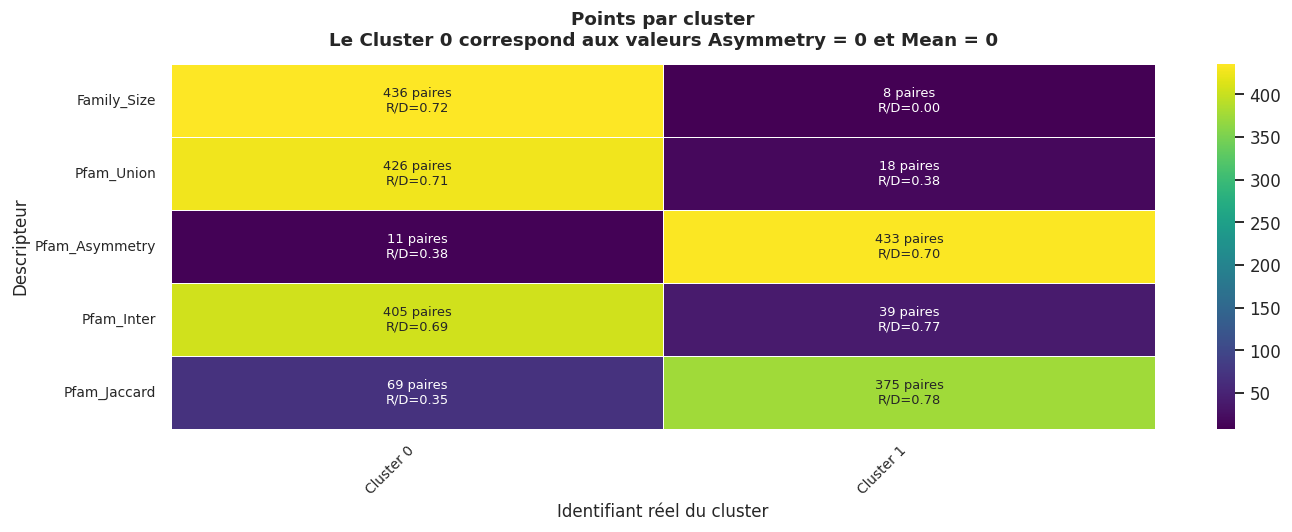

In [23]:
# Heatmap
fig, ax = plt.subplots(figsize=(13, 5))

nan_mask = cluster_comparison.isna()

sns.heatmap(
    cluster_comparison,
    annot=annot_matrix,
    fmt="",
    cmap="viridis",
    cbar=True,
    mask=nan_mask,
    linewidths=0.5,
    linecolor="white",
    ax=ax,
    annot_kws={"size": 8.5}
)

# Hachures pour les clusters absents
for row_index in range(cluster_comparison.shape[0]):
    for column_index in range(cluster_comparison.shape[1]):
        if nan_mask.iloc[row_index, column_index]:
            ax.add_patch(
                plt.Rectangle(
                    (column_index, row_index),
                    1,
                    1,
                    fill=True,
                    color="lightgrey",
                    hatch="//",
                    alpha=0.6
                )
            )

ax.set_title(
    "Points par cluster\n"
    "Le Cluster 0 correspond aux valeurs Asymmetry = 0 et Mean = 0",
    fontsize=12,
    fontweight="bold",
    pad=12
)

ax.set_xlabel("Identifiant réel du cluster", fontsize=11)
ax.set_ylabel("Descripteur", fontsize=11)

ax.set_xticklabels(
    columns,
    rotation=45,
    ha="right",
    fontsize=9
)

ax.set_yticklabels(
    selected_descriptors,
    rotation=0,
    fontsize=9
)

plt.tight_layout()
plt.show()

In [24]:
# Classement des clusters par centre décroissant pour chaque descripteur

X_all_scaled_df = pd.DataFrame(
    X_all_scaled,
    columns=X_all.columns,
    index=X_train.index
)

ordered_clusters_by_descriptor = {}
cluster_centers_by_descriptor = {}
ordered_rows = []

for descriptor in selected_descriptors:
    labels = labels_by_descriptor[descriptor]

    valid_mask = (
        labels.notna()
        & X_all_scaled_df[descriptor].notna()
    )

    values = X_all_scaled_df.loc[valid_mask, descriptor]
    labels_valid = labels.loc[valid_mask].astype(int)

    centers = values.groupby(labels_valid).mean()
    ordered_clusters = centers.sort_values(
        ascending=False
    ).index.tolist()

    ordered_clusters_by_descriptor[descriptor] = ordered_clusters
    cluster_centers_by_descriptor[descriptor] = centers

    classification_valid = classifications.loc[valid_mask]

    row_sizes = {}
    row_ratios = {}

    for cluster_id in ordered_clusters:
        cluster_mask = labels_valid == cluster_id

        n_pairs = int(cluster_mask.sum())
        n_redondant = int(
            ((classification_valid == 0) & cluster_mask).sum()
        )
        n_divergent = int(
            ((classification_valid == 1) & cluster_mask).sum()
        )

        ratio = (
            n_redondant / n_divergent
            if n_divergent > 0
            else np.inf
        )

        row_sizes[cluster_id] = n_pairs
        row_ratios[cluster_id] = ratio

    ordered_rows.append({
        "descriptor": descriptor,
        "clusters": ordered_clusters,
        "sizes": row_sizes,
        "ratios": row_ratios
    })


# Nombre maximal de clusters
max_clusters = max(
    len(row["clusters"])
    for row in ordered_rows
)

rank_columns = [
    f"Rang {rank}"
    for rank in range(1, max_clusters + 1)
]

cluster_comparison_ordered = pd.DataFrame(
    np.nan,
    index=selected_descriptors,
    columns=rank_columns,
    dtype=float
)

annotations_ordered = pd.DataFrame(
    "",
    index=selected_descriptors,
    columns=rank_columns,
    dtype=object
)

cluster_labels_ordered = pd.DataFrame(
    "",
    index=selected_descriptors,
    columns=rank_columns,
    dtype=object
)


for row in ordered_rows:
    descriptor = row["descriptor"]

    for rank, cluster_id in enumerate(row["clusters"]):
        column = f"Rang {rank + 1}"

        n_pairs = row["sizes"][cluster_id]
        ratio = row["ratios"][cluster_id]
        center = cluster_centers_by_descriptor[
            descriptor
        ].loc[cluster_id]

        cluster_comparison_ordered.loc[
            descriptor, column
        ] = n_pairs

        cluster_labels_ordered.loc[
            descriptor, column
        ] = f"Cluster {cluster_id}"

        ratio_text = (
            f"{ratio:.2f}"
            if not np.isinf(ratio)
            else "inf"
        )

        annotations_ordered.loc[
            descriptor, column
        ] = (
            f"Cluster {cluster_id}\n"
            f"{n_pairs} paires\n"
            f"R/D={ratio_text}"
        )


# Affichage de l'ordre des centres
centers_ordered_df = pd.DataFrame(
    {
        descriptor: pd.Series(
            cluster_centers_by_descriptor[descriptor]
            .sort_values(ascending=False)
            .values
        )
        for descriptor in selected_descriptors
    }
)

display(centers_ordered_df)

,Family_Size,Pfam_Union,Pfam_Asymmetry,Pfam_Inter,Pfam_Jaccard
0,7.110895,4.111664,5.058971,2.668731,0.370470
1,-0.130475,-0.173732,-0.128519,-0.256989,-2.013427


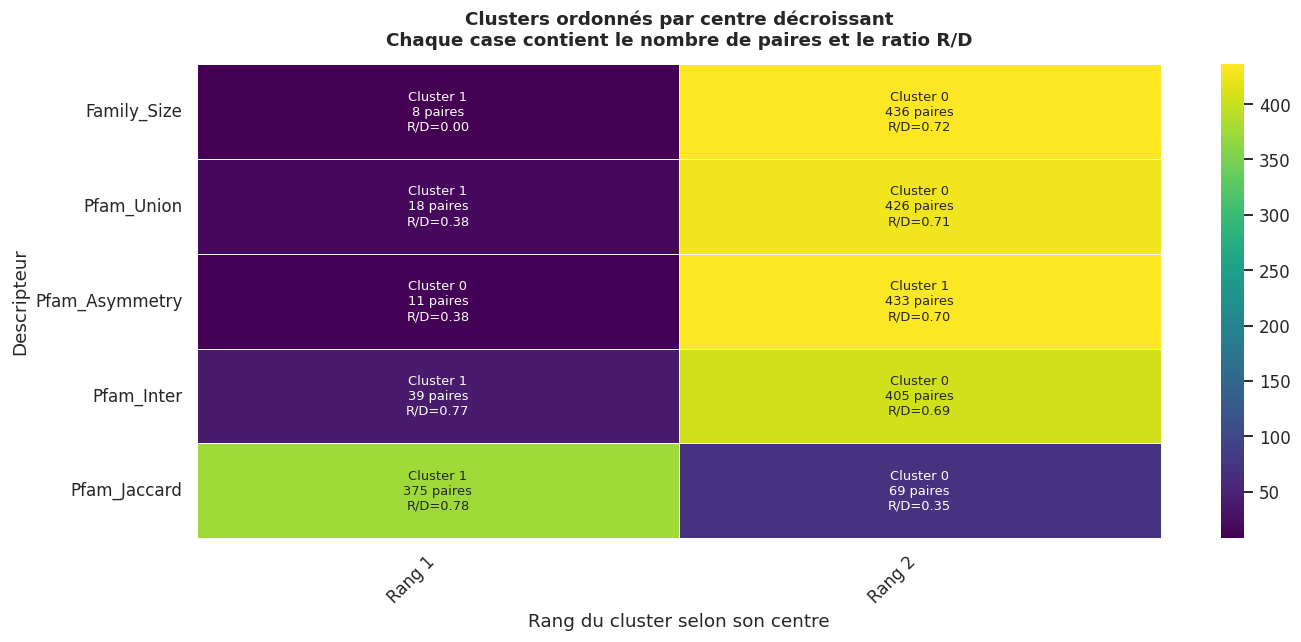

In [25]:
# Heatmap du nombre de paires
fig, ax = plt.subplots(figsize=(13, 6))

nan_mask = cluster_comparison_ordered.isna()

sns.heatmap(
    cluster_comparison_ordered,
    annot=annotations_ordered,
    fmt="",
    cmap="viridis",
    cbar=True,
    mask=nan_mask,
    linewidths=0.5,
    linecolor="white",
    ax=ax,
    annot_kws={"size": 8.5}
)

# Hachures pour les rangs inexistants
for row_index in range(
    cluster_comparison_ordered.shape[0]
):
    for column_index in range(
        cluster_comparison_ordered.shape[1]
    ):
        if nan_mask.iloc[row_index, column_index]:
            ax.add_patch(
                plt.Rectangle(
                    (column_index, row_index),
                    1,
                    1,
                    fill=True,
                    color="lightgrey",
                    hatch="//",
                    alpha=0.6
                )
            )

ax.set_title(
    "Clusters ordonnés par centre décroissant\n"
    "Chaque case contient le nombre de paires et le ratio R/D",
    fontsize=12,
    fontweight="bold",
    pad=12
)

ax.set_xlabel(
    "Rang du cluster selon son centre"
)
ax.set_ylabel("Descripteur")

ax.set_xticklabels(
    rank_columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(
    selected_descriptors,
    rotation=0
)

plt.tight_layout()
plt.show()

## Matrices d'adjacences

In [26]:
family_adjacency_matrices = {}

for family_name in X_top_5_scaled.columns:

    optimal_k = 2

    X_family = X_top_5_scaled[[family_name]]

    kmeans_family = KMeans(
        n_clusters=optimal_k,
        n_init=n_init,
        random_state=random_state,
        init="k-means++"
    )

    labels_family = kmeans_family.fit_predict(X_family)

    Z_family_binary = pd.get_dummies(labels_family).astype(int)

    adjacency_matrix = (
        Z_family_binary.values @ Z_family_binary.values.T
    )

    np.fill_diagonal(adjacency_matrix, 0)

    family_adjacency_matrices[family_name] = adjacency_matrix

    print(
        f"{family_name} : {adjacency_matrix.shape}, "
        f"{adjacency_matrix.sum() / 2:.0f} paires"
    )

Family_Size : (444, 444), 94858 paires
Pfam_Union : (444, 444), 90678 paires
Pfam_Asymmetry : (444, 444), 93583 paires
Pfam_Inter : (444, 444), 82551 paires
Pfam_Jaccard : (444, 444), 72471 paires


In [27]:
for family_name, adjacency_matrix in family_adjacency_matrices.items():

    adjacency_df = pd.DataFrame(
        adjacency_matrix,
        index=X_top_5_scaled.index,
        columns=X_top_5_scaled.index
    )

    adjacency_df.to_csv(
        f"Données/adjacency/lda/family/adjacency_matrix_silh_{family_name}.csv"
    )

    print(f"Matrice sauvegardée pour : {family_name}")

Matrice sauvegardée pour : Family_Size
Matrice sauvegardée pour : Pfam_Union
Matrice sauvegardée pour : Pfam_Asymmetry
Matrice sauvegardée pour : Pfam_Inter
Matrice sauvegardée pour : Pfam_Jaccard


### Matrice agrégées

In [30]:
family_groups = {"Pfam" : selected_descriptors
}

group_adjacency_matrices = {}

for group_name, descriptors in family_groups.items():

    available_descriptors = [
        descriptor
        for descriptor in descriptors
        if descriptor in family_adjacency_matrices
    ]

    if not available_descriptors:
        print(f"Aucune matrice disponible pour {group_name}")
        continue

    group_matrix = np.sum(
        [
            family_adjacency_matrices[descriptor]
            for descriptor in available_descriptors
        ],
        axis=0
    )

    group_adjacency_matrices[group_name] = group_matrix

    print(
        f"{group_name} : "
        f"{available_descriptors} -> {group_matrix.shape}"
    )

Pfam : ['Family_Size', 'Pfam_Union', 'Pfam_Asymmetry', 'Pfam_Inter', 'Pfam_Jaccard'] -> (444, 444)


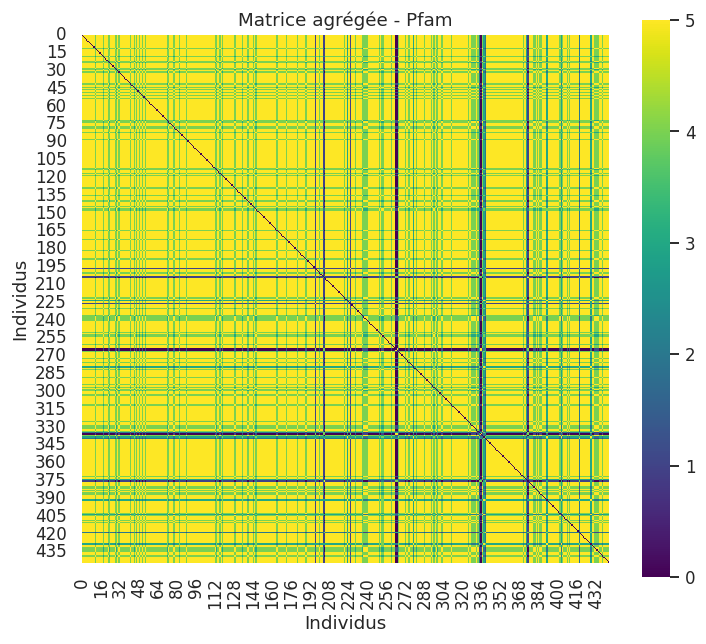

In [31]:
fig, axes = plt.subplots(
    1,
    len(group_adjacency_matrices),
    figsize=(7 * len(group_adjacency_matrices), 6)
)

if len(group_adjacency_matrices) == 1:
    axes = [axes]

for ax, (family_name, matrix) in zip(
    axes,
    group_adjacency_matrices.items()
):
    sns.heatmap(
        matrix,
        ax=ax,
        cmap="viridis",
        square=True,
        cbar=True
    )

    ax.set_title(f"Matrice agrégée - {family_name}")
    ax.set_xlabel("Individus")
    ax.set_ylabel("Individus")

plt.tight_layout()
plt.show()

In [32]:
# Additionner les matrices d'adjacence de toutes les descripteurs et compter les nombres dans la matrice résultante
total_adjacency_sum = np.zeros_like(list(family_adjacency_matrices.values())[0])
for adjacency_matrix in family_adjacency_matrices.values():
    total_adjacency_sum += adjacency_matrix

num_zeros = (np.sum(total_adjacency_sum == 0)  - 444 )/ 2 # Nb paires de points  même cluster pour exactement 0 descripteurs
num_ones = np.sum(total_adjacency_sum == 1) / 2 # Nb paires de points même cluster pour exactement 1 descripteur
num_twos = np.sum(total_adjacency_sum == 2) / 2 # Nb paires de points même cluster pour exactement 2 descripteurs
num_threes = np.sum(total_adjacency_sum == 3) / 2 # Nb paires de points même cluster pour exactement 3 descripteurs
num_fours = np.sum(total_adjacency_sum == 4) / 2 # Nb paires de points même cluster pour exactement 4 descripteurs
num_fives = np.sum(total_adjacency_sum == 5) / 2 # Nb paires de points même cluster pour exactement 5 descripteurs

print(f"Nombre de paires de points dans le même cluster pour exactement 0 descripteurs: {num_zeros:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 1 descripteur: {num_ones:.0f}")
print(f"\nNombre de paires de points dans le même cluster pour exactement 2 descripteurs: {num_twos:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 3 descripteurs: {num_threes:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 4 descripteurs: {num_fours:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 5 descripteurs: {num_fives:.0f}")

Nombre de paires de points dans le même cluster pour exactement 0 descripteurs: 1495
Nombre de paires de points dans le même cluster pour exactement 1 descripteur: 2235

Nombre de paires de points dans le même cluster pour exactement 2 descripteurs: 1738
Nombre de paires de points dans le même cluster pour exactement 3 descripteurs: 3799
Nombre de paires de points dans le même cluster pour exactement 4 descripteurs: 28362
Nombre de paires de points dans le même cluster pour exactement 5 descripteurs: 60717


In [33]:
num_twos + num_threes + num_ones + num_zeros + num_fours + num_fives

np.float64(98346.0)

In [34]:
print("\nDistribution des valeurs dans la matrice :")
total_count = 0
total_pairs = (total_adjacency_sum.size - 444) / 2

for v in range(len(selected_descriptors) + 1):
    if v == 0:
        count = np.sum(total_adjacency_sum == v) - 444
        count = count / 2
    else:
        count = np.sum(total_adjacency_sum == v) / 2

    pct = 100 * count / total_pairs
    print(f"  Valeur {v} : {int(count):,} paires ({pct:.1f}%)")
    total_count += count



Distribution des valeurs dans la matrice :
  Valeur 0 : 1,495 paires (1.5%)
  Valeur 1 : 2,235 paires (2.3%)
  Valeur 2 : 1,738 paires (1.8%)
  Valeur 3 : 3,799 paires (3.9%)
  Valeur 4 : 28,362 paires (28.8%)
  Valeur 5 : 60,717 paires (61.7%)
